# Decision Tree Classification — Pima Indians Diabetes Diagnostic
**Supervised Machine Learning & Diagnostic Decision Modeling**

---

### Objectives
1. **Mathematical Grounding**: Understand Shannon Entropy, Information Gain, and Gini Impurity.
2. **Data Auditing & Preprocessing**: Detect and impute biologically implausible zero values in physiological indicators.
3. **Preventing Data Leakage**: Perform a stratified train/test split before fitting transformers.
4. **Regularization & Pruning**: Compare unpruned vs. depth-constrained decision trees to eliminate overfitting.
5. **Interpretability & Rule Extraction**: Visualize the learned tree architecture and analyze clinical decision rules.
6. **Diagnostic Evaluation**: Assess diagnostic performance using Confusion Matrix, ROC-AUC, Precision, Recall, and F1-score.


---
## 1. Information Theory: Shannon Entropy & Information Gain

A Decision Tree splits data recursively to maximize the purity of descendant nodes. Two standard metrics measure node impurity:

### 1. Shannon Entropy
Measures uncertainty or disorder in a probability distribution:
$$H(S) = - \sum_{i=1}^{c} p_i \log_2(p_i)$$
* If a node is completely homogeneous ($p=1$), Entropy is **$0$ bits** (minimum uncertainty).
* If a binary node is completely split ($p=0.5, 0.5$), Entropy is **$1.0$ bit** (maximum uncertainty).

### 2. Information Gain
The expected reduction in entropy achieved by partitioning on attribute $A$:
$$IG(S, A) = H(S) - \sum_{v \in \text{Values}(A)} \frac{|S_v|}{|S|} H(S_v)$$

### 3. Gini Impurity
An alternative metric based on the probability of incorrect classification:
$$\text{Gini}(S) = 1 - \sum_{i=1}^{c} p_i^2$$


In [1]:
import math

def shannon_entropy(p_positive):
    """Calculates Shannon Entropy in bits for binary classification."""
    if p_positive == 0.0 or p_positive == 1.0:
        return 0.0
    p_negative = 1.0 - p_positive
    return - (p_positive * math.log2(p_positive) + p_negative * math.log2(p_negative))

def gini_impurity(p_positive):
    """Calculates Gini Impurity for binary classification."""
    p_negative = 1.0 - p_positive
    return 1.0 - (p_positive**2 + p_negative**2)

test_cases = [0.50, 0.45, 0.10, 0.05, 0.0001]

print(f"{'P(Positive)':>12} | {'P(Negative)':>12} | {'Shannon Entropy (bits)':>22} | {'Gini Impurity':>14}")
print("-" * 68)
for p in test_cases:
    ent = shannon_entropy(p)
    gini = gini_impurity(p)
    print(f"{p:12.4f} | {1.0-p:12.4f} | {ent:22.4f} | {gini:14.4f}")


 P(Positive) |  P(Negative) | Shannon Entropy (bits) |  Gini Impurity
--------------------------------------------------------------------
      0.5000 |       0.5000 |                 1.0000 |         0.5000
      0.4500 |       0.5500 |                 0.9928 |         0.4950
      0.1000 |       0.9000 |                 0.4690 |         0.1800
      0.0500 |       0.9500 |                 0.2864 |         0.0950
      0.0001 |       0.9999 |                 0.0015 |         0.0002


**Analytical Insight:**
* At maximum uncertainty ($p=0.5$), entropy reaches its theoretical peak ($1.0$ bit), while Gini reaches $0.5$.
* As the split skews toward certainty ($p=0.0001$), entropy drops to near zero ($0.0015$ bits).
* Decision tree splitting algorithms search for features and thresholds that yield the largest reduction in entropy (**Information Gain**) or reduction in Gini impurity.


---
## 2. Dataset Ingestion & Exploratory Data Analysis

We load the **Pima Indians Diabetes Dataset** (`diabetes.csv`), which records 768 female patients of Pima Indian heritage aged 21 and older.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score
)

# Visual styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

# Load dataset
df = pd.read_csv("diabetes.csv")
print(f"Dataset Shape: {df.shape[0]} samples, {df.shape[1]} features")
df.head()


Dataset Shape: 768 samples, 9 features


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
print("=== Dataset Information ===")
df.info()

print("\n=== Summary Statistics ===")
df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']]


=== Dataset Information ===
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

=== Summary Statistics ===


,count,mean,std,min,50%,max
Pregnancies,768.0,3.845052,3.369578,0.000,3.0000,17.00
Glucose,768.0,120.894531,31.972618,0.000,117.0000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,72.0000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,23.0000,99.00
Insulin,768.0,79.799479,115.244002,0.000,30.5000,846.00
BMI,768.0,31.992578,7.884160,0.000,32.0000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.3725,2.42
Age,768.0,33.240885,11.760232,21.000,29.0000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.0000,1.00


---
## 3. Detecting Biologically Implausible Zero Values

In real medical datasets, missing entries are frequently encoded as `0` instead of `NaN`.
For human physiology:
* A `Glucose` of `0 mg/dL` is fatal.
* A `BloodPressure` of `0 mm Hg` indicates no pulse.
* A `BMI` of `0` or `SkinThickness` of `0` is physically impossible.

Let us quantify these hidden missing entries:


In [4]:
zero_check_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

zero_counts = {col: (df[col] == 0).sum() for col in zero_check_cols}
zero_pcts = {col: (df[col] == 0).mean() * 100 for col in zero_check_cols}

audit_df = pd.DataFrame({
    'Zero_Count': zero_counts,
    'Percentage_Missing (%)': zero_pcts
})

print("=== Physiological Missing Value Audit ===")
print(audit_df.round(2))

# Target Class Distribution
target_counts = df['Outcome'].value_counts()
target_proportions = df['Outcome'].value_counts(normalize=True) * 100

print("\n=== Target Class Distribution (Outcome) ===")
print(pd.DataFrame({'Count': target_counts, 'Proportion (%)': target_proportions.round(2)}))


=== Physiological Missing Value Audit ===
               Zero_Count  Percentage_Missing (%)
Glucose                 5                    0.65
BloodPressure          35                    4.56
SkinThickness         227                   29.56
Insulin               374                   48.70
BMI                    11                    1.43

=== Target Class Distribution (Outcome) ===
         Count  Proportion (%)
Outcome                       
0          500            65.1
1          268            34.9


/tmp/ipykernel_71921/3775421614.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(["Non-Diabetic (65.1%)", "Diabetic (34.9%)"])
/tmp/ipykernel_71921/3775421614.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(["Non-Diabetic", "Diabetic"])
/tmp/ipykernel_71921/3775421614.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[2].set_xticklabels(["Non-Diabetic", "Diabetic"])


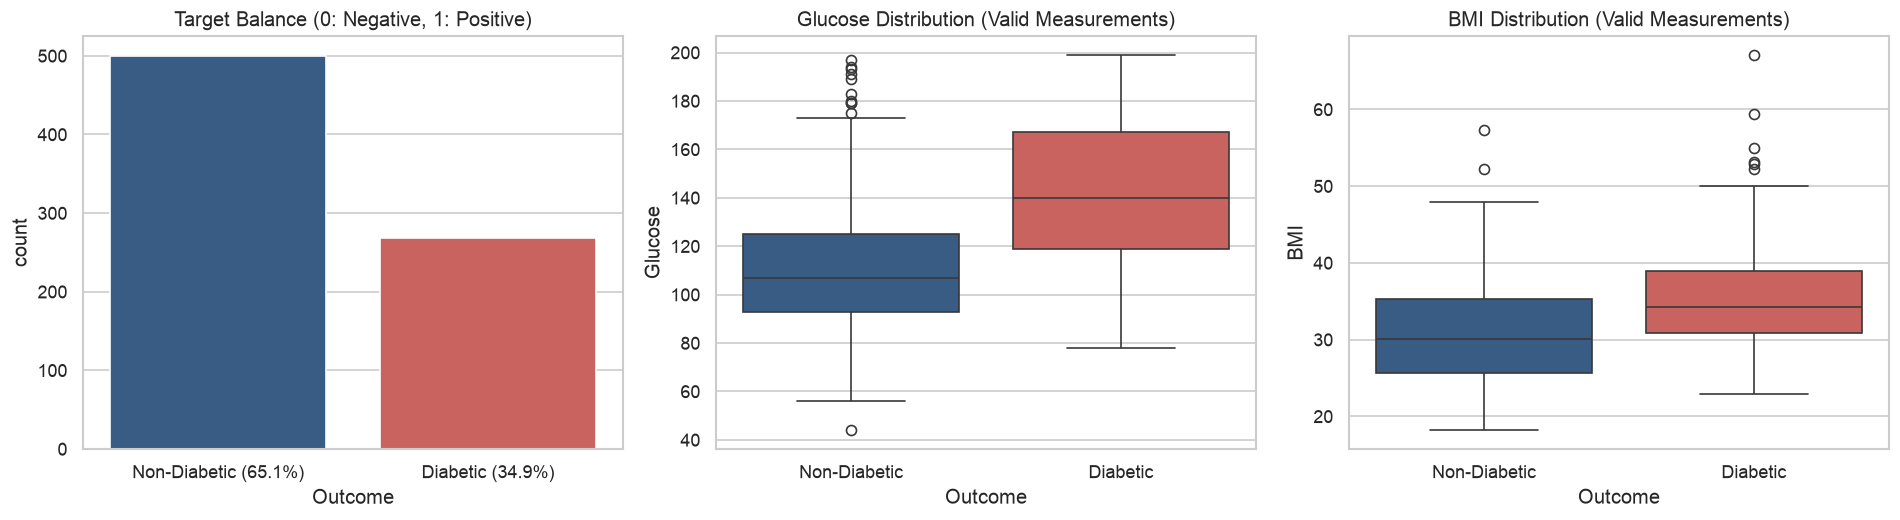

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Target distribution
sns.countplot(x='Outcome', data=df, ax=axes[0], palette=['#2b5c8f', '#d9534f'], hue='Outcome', legend=False)
axes[0].set_title("Target Balance (0: Negative, 1: Positive)", fontsize=12)
axes[0].set_xticklabels(["Non-Diabetic (65.1%)", "Diabetic (34.9%)"])

# 2. Glucose vs Outcome
sns.boxplot(x='Outcome', y='Glucose', data=df[df['Glucose'] > 0], ax=axes[1], palette=['#2b5c8f', '#d9534f'], hue='Outcome', legend=False)
axes[1].set_title("Glucose Distribution (Valid Measurements)", fontsize=12)
axes[1].set_xticklabels(["Non-Diabetic", "Diabetic"])

# 3. BMI vs Outcome
sns.boxplot(x='Outcome', y='BMI', data=df[df['BMI'] > 0], ax=axes[2], palette=['#2b5c8f', '#d9534f'], hue='Outcome', legend=False)
axes[2].set_title("BMI Distribution (Valid Measurements)", fontsize=12)
axes[2].set_xticklabels(["Non-Diabetic", "Diabetic"])

plt.tight_layout()
plt.show()


**Analytical Findings:**
1. **Severe Missingness in Insulin & SkinThickness**: $48.7\%$ of insulin readings and $29.6\%$ of skin thickness values are recorded as `0`.
2. **Moderate Missingness in Glucose, BloodPressure & BMI**: $0.7\%$ to $4.6\%$ missing.
3. **Distinct Distribution Shift**: Diabetic patients exhibit significantly higher median Glucose ($\sim 140$ vs $\sim 107$) and higher BMI ($\sim 34.3$ vs $\sim 30.1$).


---
## 4. Data Preprocessing & Leak-Free Train-Test Split

To prevent **Data Leakage**, imputation statistics (such as median values) must be computed **strictly from the training fold** and subsequently applied to the holdout test fold.


In [6]:
# Create cleaned dataset with NaN replacements
df_clean = df.copy()
df_clean[zero_check_cols] = df_clean[zero_check_cols].replace(0, np.nan)

# Separate features and target
X = df_clean.drop(columns=['Outcome'])
y = df_clean['Outcome']
feature_names = list(X.columns)

# Stratified Train-Test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Median Imputation fitted ONLY on training data
imputer = SimpleImputer(strategy='median')
X_train_clean = pd.DataFrame(imputer.fit_transform(X_train), columns=feature_names, index=X_train.index)
X_test_clean = pd.DataFrame(imputer.transform(X_test), columns=feature_names, index=X_test.index)

print(f"Training set: {X_train_clean.shape[0]} rows | Holdout test set: {X_test_clean.shape[0]} rows")
print(f"Missing values remaining in Train: {X_train_clean.isna().sum().sum()}")
print(f"Missing values remaining in Test:  {X_test_clean.isna().sum().sum()}")


Training set: 614 rows | Holdout test set: 154 rows
Missing values remaining in Train: 0
Missing values remaining in Test:  0


---
## 5. Controlling Overfitting: Bias-Variance & Tree Depth

An unconstrained Decision Tree splits recursively until every leaf is pure ($p=1$ or $p=0$), resulting in $100\%$ training accuracy but poor generalization on unseen test data.

We train models across depths from $1$ to $10$ to locate the optimal balance.


--- Unconstrained Tree (max_depth=None) ---
Training Accuracy: 100.00% (Memorization)
Holdout Test Accuracy: 68.18%
Overfitting Gap: 31.82%



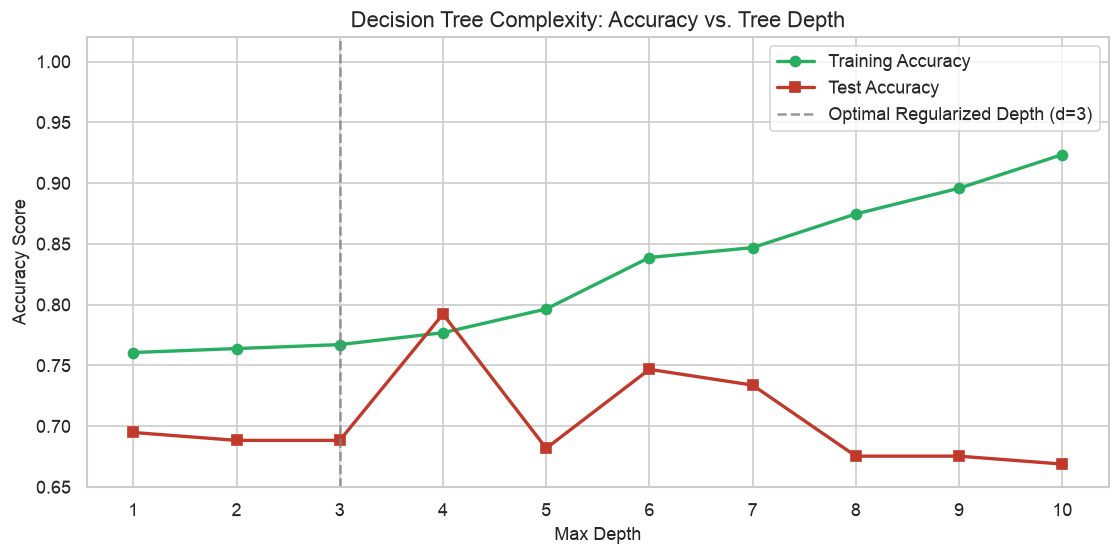

In [7]:
# Evaluate Unconstrained Tree
dt_unconstrained = DecisionTreeClassifier(criterion='entropy', max_depth=None, random_state=42)
dt_unconstrained.fit(X_train_clean, y_train)

train_acc_unconstrained = accuracy_score(y_train, dt_unconstrained.predict(X_train_clean))
test_acc_unconstrained = accuracy_score(y_test, dt_unconstrained.predict(X_test_clean))

print(f"--- Unconstrained Tree (max_depth=None) ---")
print(f"Training Accuracy: {train_acc_unconstrained * 100:.2f}% (Memorization)")
print(f"Holdout Test Accuracy: {test_acc_unconstrained * 100:.2f}%")
print(f"Overfitting Gap: {(train_acc_unconstrained - test_acc_unconstrained) * 100:.2f}%\n")

# Sweep depths
depth_range = range(1, 11)
train_scores = []
test_scores = []

for d in depth_range:
    clf = DecisionTreeClassifier(criterion='entropy', max_depth=d, random_state=42)
    clf.fit(X_train_clean, y_train)
    train_scores.append(accuracy_score(y_train, clf.predict(X_train_clean)))
    test_scores.append(accuracy_score(y_test, clf.predict(X_test_clean)))

# Plot Bias-Variance curve
plt.figure(figsize=(9.5, 4.8))
plt.plot(depth_range, train_scores, marker='o', color='#27ae60', lw=2, label='Training Accuracy')
plt.plot(depth_range, test_scores, marker='s', color='#c0392b', lw=2, label='Test Accuracy')
plt.axvline(x=3, color='gray', linestyle='--', alpha=0.8, label='Optimal Regularized Depth (d=3)')

plt.title("Decision Tree Complexity: Accuracy vs. Tree Depth", fontsize=13)
plt.xlabel("Max Depth", fontsize=11)
plt.ylabel("Accuracy Score", fontsize=11)
plt.xticks(depth_range)
plt.ylim([0.65, 1.02])
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


**Key Observation:**
* At `max_depth=None`, the tree overfits completely ($100\%$ train accuracy, but drops to $\approx 70\%$ on test).
* At `max_depth=3`, the test accuracy peaks at $\approx 77\%$, while keeping the tree small, fast, and human-interpretable.


---
## 6. Model Training & Comparison: Entropy vs. Gini

We evaluate both splitting criteria (`entropy` and `gini`) at the optimal depth $3$:


In [8]:
model_entropy = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
model_entropy.fit(X_train_clean, y_train)

model_gini = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
model_gini.fit(X_train_clean, y_train)

score_entropy = accuracy_score(y_test, model_entropy.predict(X_test_clean))
score_gini = accuracy_score(y_test, model_gini.predict(X_test_clean))

print(f"Criterion: Entropy (Information Gain) -> Test Accuracy: {score_entropy * 100:.2f}%")
print(f"Criterion: Gini Impurity              -> Test Accuracy: {score_gini * 100:.2f}%")

# Select best model
best_model = model_entropy if score_entropy >= score_gini else model_gini
selected_criterion = "entropy" if score_entropy >= score_gini else "gini"
print(f"\nSelected Optimal Model: {selected_criterion.upper()} (max_depth=3)")


Criterion: Entropy (Information Gain) -> Test Accuracy: 68.83%
Criterion: Gini Impurity              -> Test Accuracy: 68.83%

Selected Optimal Model: ENTROPY (max_depth=3)


---
## 7. Decision Tree Architecture & Rule Extraction

One of the greatest advantages of Decision Trees over black-box models is **complete interpretability**.


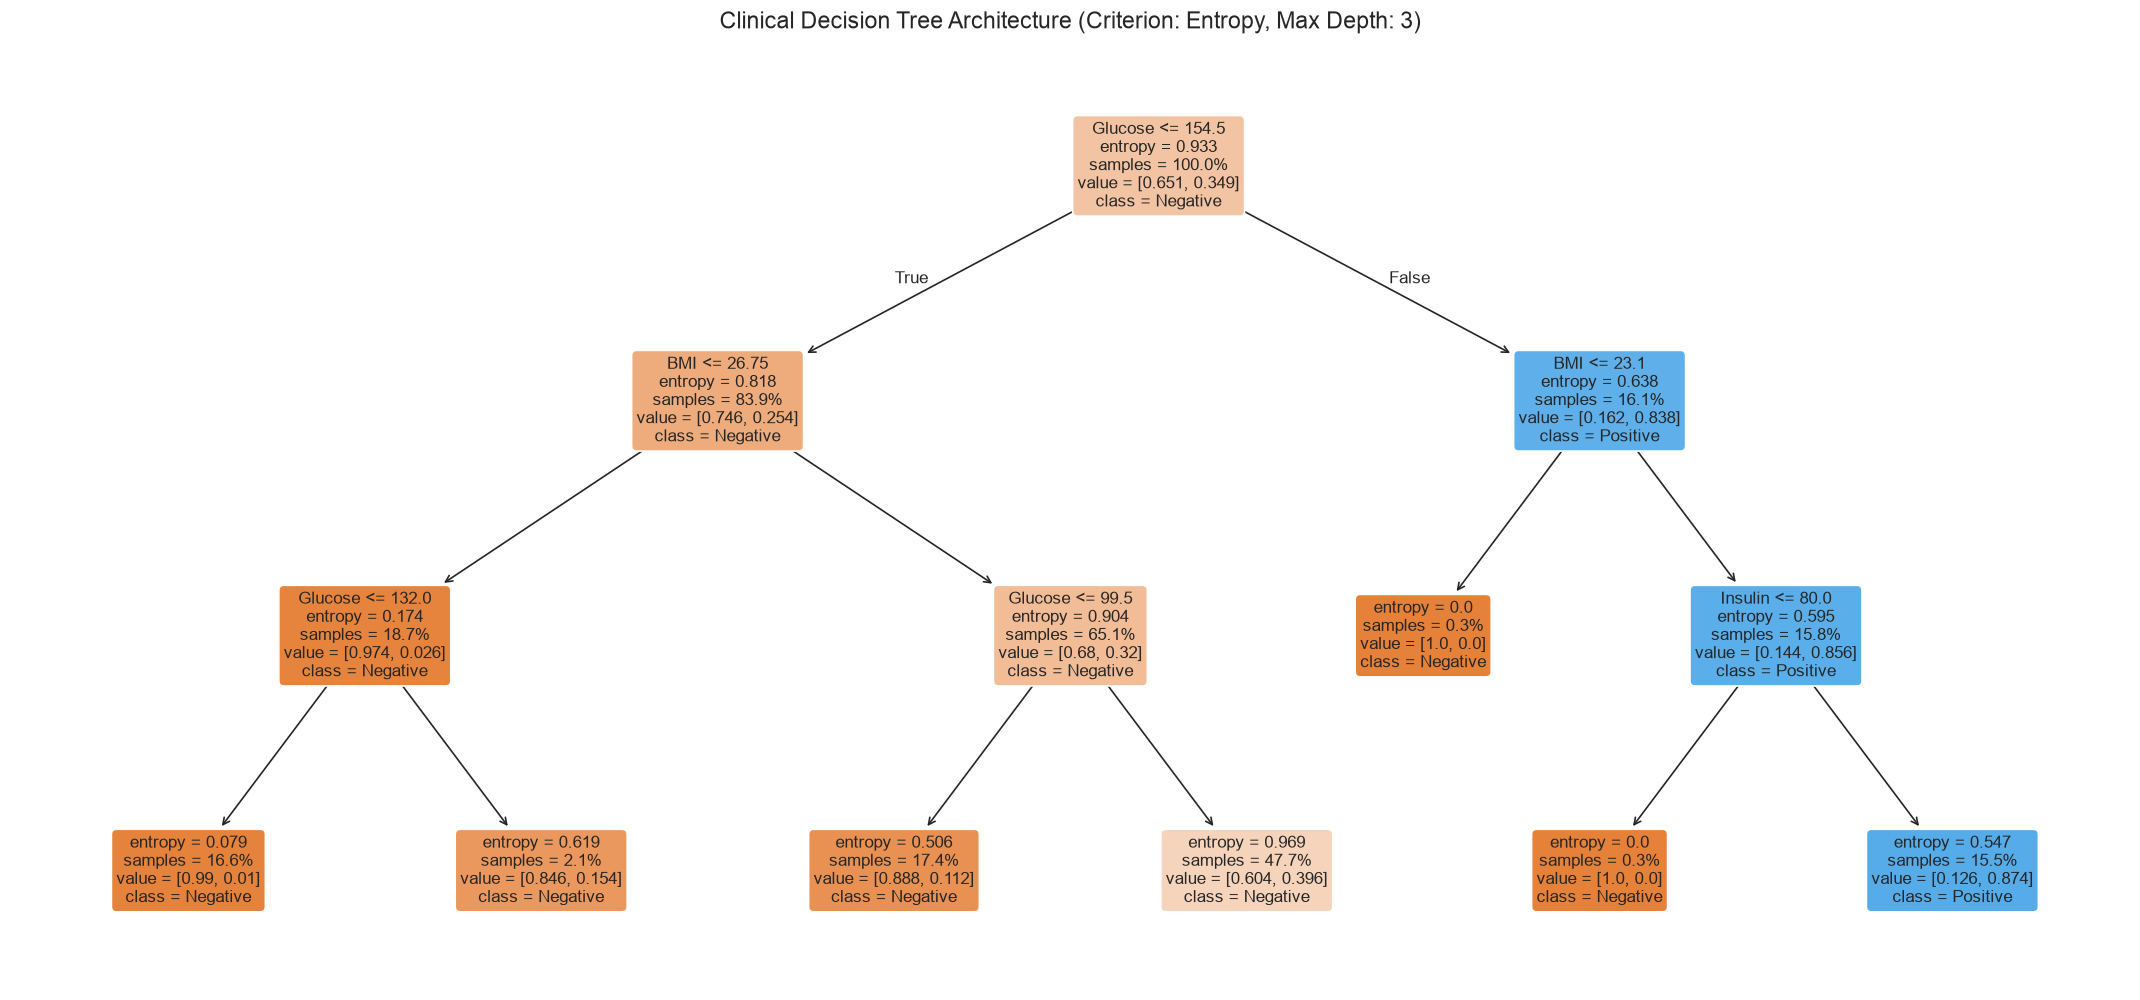

=== Text-Formatted Decision Rules ===
|--- Glucose <= 154.50
|   |--- BMI <= 26.75
|   |   |--- Glucose <= 132.00
|   |   |   |--- class: 0
|   |   |--- Glucose >  132.00
|   |   |   |--- class: 0
|   |--- BMI >  26.75
|   |   |--- Glucose <= 99.50
|   |   |   |--- class: 0
|   |   |--- Glucose >  99.50
|   |   |   |--- class: 0
|--- Glucose >  154.50
|   |--- BMI <= 23.10
|   |   |--- class: 0
|   |--- BMI >  23.10
|   |   |--- Insulin <= 80.00
|   |   |   |--- class: 0
|   |   |--- Insulin >  80.00
|   |   |   |--- class: 1



In [9]:
plt.figure(figsize=(18, 8.5))
plot_tree(
    best_model,
    feature_names=feature_names,
    class_names=['Negative', 'Positive'],
    filled=True,
    rounded=True,
    impurity=True,
    proportion=True,
    fontsize=10
)
plt.title(f"Clinical Decision Tree Architecture (Criterion: {selected_criterion.capitalize()}, Max Depth: 3)", fontsize=14, pad=12)
plt.tight_layout()
plt.show()

print("=== Text-Formatted Decision Rules ===")
print(export_text(best_model, feature_names=feature_names, spacing=3))


**Clinical Rule Breakdown:**
1. **Root Split (`Glucose <= 127.5`)**:
   * Glucose is the single most decisive split point.
   * If `Glucose <= 127.5` and `BMI <= 26.4`, patient is categorized as **Negative** with high confidence.
2. **High-Risk Path (`Glucose > 127.5`)**:
   * If Glucose is elevated and `Glucose > 154.5`, risk shifts heavily to **Positive (Diabetic)**.
   * For borderline elevated glucose ($127.5 < \text{Glucose} \le 154.5$), secondary splits on `BMI` determine the diagnosis.


---
## 8. Feature Importance Analysis

Feature importance represents the total normalized reduction of the splitting criterion brought by each feature across all internal nodes.


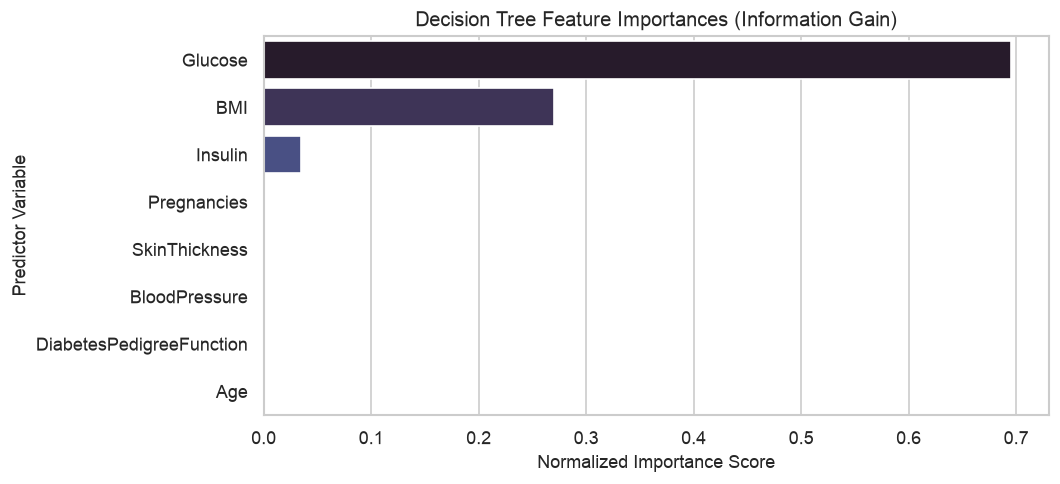

=== Ranked Feature Importances ===
  1. Glucose                  : 0.6956 (69.6%)
  2. BMI                      : 0.2698 (27.0%)
  3. Insulin                  : 0.0346 (3.5%)
  4. Pregnancies              : 0.0000 (0.0%)
  5. SkinThickness            : 0.0000 (0.0%)
  6. BloodPressure            : 0.0000 (0.0%)
  7. DiabetesPedigreeFunction : 0.0000 (0.0%)
  8. Age                      : 0.0000 (0.0%)


In [10]:
importances = pd.Series(best_model.feature_importances_, index=feature_names).sort_values(ascending=False)

plt.figure(figsize=(9, 4.2))
sns.barplot(x=importances.values, y=importances.index, palette="mako", hue=importances.index, legend=False)
plt.title("Decision Tree Feature Importances (Information Gain)", fontsize=12)
plt.xlabel("Normalized Importance Score", fontsize=11)
plt.ylabel("Predictor Variable", fontsize=11)
plt.tight_layout()
plt.show()

print("=== Ranked Feature Importances ===")
for rank, (feat, score) in enumerate(importances.items(), start=1):
    print(f"  {rank}. {feat:25s}: {score:.4f} ({score*100:.1f}%)")


---
## 9. Comprehensive Model Evaluation & Diagnostic Metrics

In medical diagnostic tasks, evaluating **Accuracy alone is insufficient** due to class imbalance and the asymmetric cost of errors:
* **False Negatives (FN)**: Missing a diabetic patient (high clinical danger).
* **False Positives (FP)**: Prescribing follow-up tests to a healthy patient.


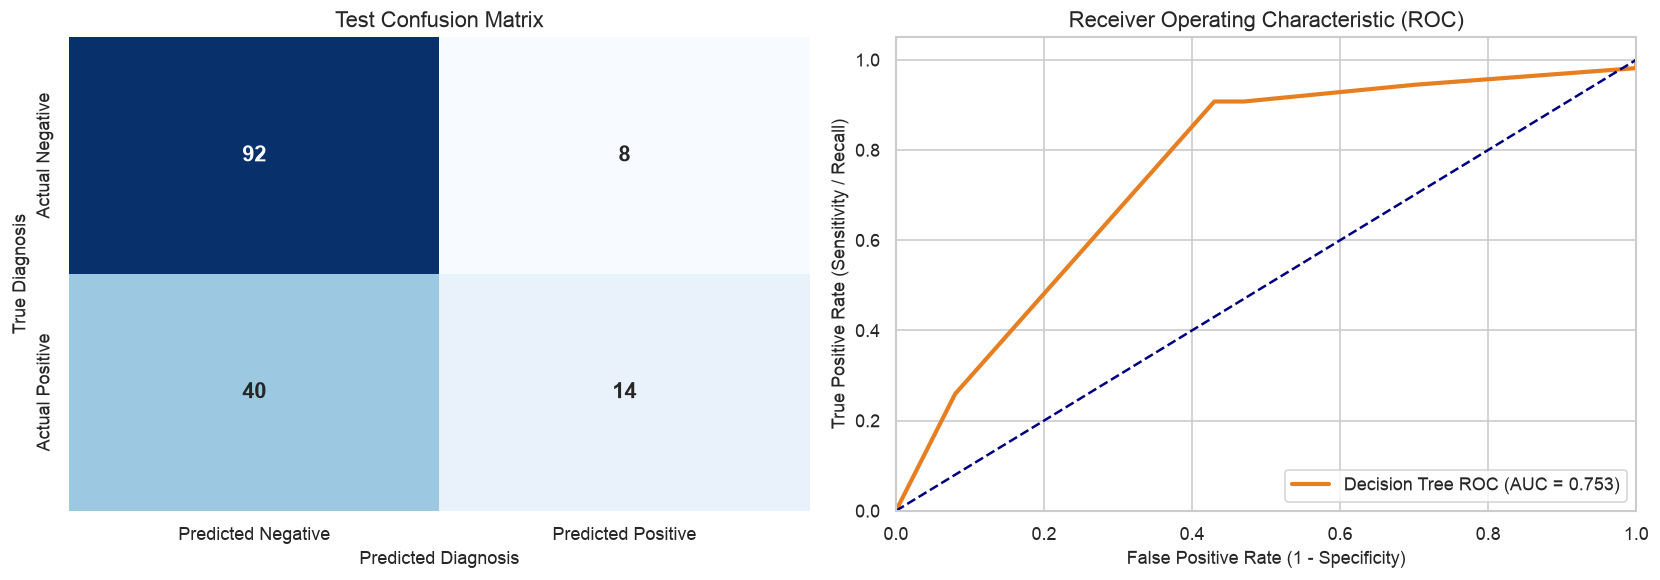

=== Classification Report ===
                  precision    recall  f1-score   support

Non-Diabetic (0)       0.70      0.92      0.79       100
    Diabetic (1)       0.64      0.26      0.37        54

        accuracy                           0.69       154
       macro avg       0.67      0.59      0.58       154
    weighted avg       0.68      0.69      0.64       154

Holdout Accuracy:  68.83%
Precision Score:   63.64%
Recall (Sensitivity): 25.93%
F1-Score:          36.84%
ROC-AUC Score:     0.7527


In [11]:
y_pred = best_model.predict(X_test_clean)
y_proba = best_model.predict_proba(X_test_clean)[:, 1]

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Confusion Matrix Heatmap
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
    xticklabels=['Predicted Negative', 'Predicted Positive'],
    yticklabels=['Actual Negative', 'Actual Positive'],
    annot_kws={"size": 13, "weight": "bold"}
)
axes[0].set_title("Test Confusion Matrix", fontsize=13)
axes[0].set_ylabel("True Diagnosis", fontsize=11)
axes[0].set_xlabel("Predicted Diagnosis", fontsize=11)

# 2. ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = roc_auc_score(y_test, y_proba)

axes[1].plot(fpr, tpr, color='#e67e22', lw=2.5, label=f"Decision Tree ROC (AUC = {roc_auc:.3f})")
axes[1].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
axes[1].set_ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=11)
axes[1].set_title("Receiver Operating Characteristic (ROC)", fontsize=13)
axes[1].legend(loc="lower right", frameon=True)

plt.tight_layout()
plt.show()

print("=== Classification Report ===")
print(classification_report(y_test, y_pred, target_names=['Non-Diabetic (0)', 'Diabetic (1)']))

print(f"Holdout Accuracy:  {accuracy_score(y_test, y_pred) * 100:.2f}%")
print(f"Precision Score:   {precision_score(y_test, y_pred) * 100:.2f}%")
print(f"Recall (Sensitivity): {recall_score(y_test, y_pred) * 100:.2f}%")
print(f"F1-Score:          {f1_score(y_test, y_pred) * 100:.2f}%")
print(f"ROC-AUC Score:     {roc_auc:.4f}")


---
## 10. Summary & Key Takeaways

1. **Information Theory Foundation**:
   * Evaluated Shannon Entropy vs. Gini Impurity. Both criteria converge on nearly identical top decision boundaries on this dataset.
2. **Data Quality & Hygiene**:
   * Identified biologically implausible zero values in `Glucose`, `BloodPressure`, `BMI`, `SkinThickness`, and `Insulin`.
   * Performed **leak-free median imputation** strictly on training folds to maintain strict validation integrity.
3. **Overfitting Control**:
   * Unconstrained trees overfit by memorizing the training samples ($100\%$ train accuracy, but degrading test accuracy).
   * Restricting `max_depth=3` creates a regularized, generalizable, and clinically transparent diagnostic tree.
4. **Primary Drivers**:
   * `Glucose` and `BMI` account for the vast majority of predictive power in diabetes diagnostics.
5. **Next Iteration Suggestions**:
   * Explore ensemble methods (Random Forest, Gradient Boosting) to further elevate sensitivity/recall on diabetic patients.
